# Use LLM to get synonyms for species annotations

In [1]:
import os
import sys
import re
import json
import pandas as pd
import numpy as np
import requests
import csv
import time
from openai import OpenAI
import libsbml
import antimony
from io import StringIO
from dataclasses import dataclass
from typing import List, Dict, Tuple, Any, Optional, Set
import matplotlib.pyplot as plt
import seaborn as sns
import traceback

# Import AMAS package
sys.path.insert(0, '/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2')
from AMAS import recommender
from AMAS import constants as cn
from AMAS import tools

# Directory paths
biomd_model_dir = '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels'
output_dir = '/Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/'

# test model
model_file = "/Users/luna/Desktop/CRBM/AMAS_proj/AMAS-v2/tests/BIOMD0000000190.xml"


In [2]:
developer_prompt = f"""You are a biomedical knowledge assistant. Your task is to normalize species names from biochemical 
models into standardized or canonical chemical names or common synonyms for ontology lookup on ChEBI. Only consider them as chemical entities, return "UNK" if not or unsure.

Here is one example:
Species: A, B, D
Model: “citric acid cycle model”
 // Display Names:
A is “acetyl-CoA”;
B is “citrate”;
C is “CoA”;
 // Reactions:
A + oxaloacetate => B + C;
E + F => D;

This should return:
A: "acetyl-CoA", "acetyl coenzyme A"
B: "citric acid", "sodium citrate", "citrate(4−)"
D: "UNK"
Reason: the reaction is likely to be the TCA cycle, where A is the substrate and B is an intermediate. D is unknown because no display names are given for its reactants.
"""

## Functions to prepare model information

In [3]:
@dataclass
class Recommendation:
    id: str  # ID for the species
    synonyms: list  # List of synonyms predicted by LLM
    candidates: list  # List of 'acc' values (accessions/identifiers)
    candidate_names: list  # List of names of the predicted candidates
    hit_count: list  # Number of hits in the synonyms
    
def find_species_with_chebi_annotations(model_file) -> Dict[str, List[str]]:
    """
    Find species in the model with existing ChEBI annotations.
    
    Args:
        model_file: Path to the SBML model file
        
    Returns:
        Dictionary mapping species IDs to their ChEBI annotation IDs
    """
    reader = libsbml.SBMLReader()
    document = reader.readSBML(model_file)
    model = document.getModel()
    
    # Extract existing ChEBI annotations using AMAS tools
    species_annotations = tools.extractExistingSpeciesAnnotation(model)
    
    # Filter to only keep ChEBI annotations
    chebi_annotations = {}
    for species_id, annotations in species_annotations.items():
        # Keep only species with ChEBI annotations
        if annotations:
            # If annotations start with 'CHEBI:' keep them
            chebi_ids = [ann for ann in annotations if ann.startswith('CHEBI:')]
            if chebi_ids:
                chebi_annotations[species_id] = chebi_ids
    
    return chebi_annotations

def get_species_display_names(model_file) -> Dict[str, str]:
    """
    Get the display names for all species in the model.
    
    Args:
        model_file: Path to the SBML model file
        
    Returns:
        Dictionary mapping species IDs to their display names
    """
    reader = libsbml.SBMLReader()
    document = reader.readSBML(model_file)
    model = document.getModel()
    names = {val.getId(): val.getName() for val in model.getListOfSpecies()}
    return names

def extract_model_info(model_file, species_ids: List[str]) -> Dict[str, Any]:
    """
    Extract display names and reactions for the specified species from antimony.
    Also includes display names of all species involved in reactions with the specified species.
    
    Args:
        model_file: Path to the SBML model file
        species_ids: List of species IDs to include
        
    Returns:
        Dictionary with model name, display names, and reactions or None if file cannot be loaded
    """
    # Load SBML file using antimony
    antimony.clearPreviousLoads()
    sbml_model = antimony.loadSBMLFile(model_file)
    if sbml_model == -1:
        print(f"Error loading SBML file: {antimony.getLastError()}")
        return {}  # Return empty dictionary instead of None
    
    antimony_string = antimony.getAntimonyString()
    # print(antimony_string)
    # Extract model name
    model_name = ""
    # Look for model name in format "model *ModelName()"
    model_pattern = re.search(r'model \*(.*?)\(\)', antimony_string)
    if model_pattern:
        model_name = model_pattern.group(1)
    # Extract model notes that appear after "model notes" and are surrounded by ```
    model_notes_pattern = re.search(r'model notes\s*```(.*?)```', antimony_string, re.DOTALL)
    if model_notes_pattern:
        model_notes = model_notes_pattern.group(1)
        # Remove HTML tags from model notes
        model_notes = re.sub(r'<[^>]*>', '', model_notes)

        # Split by newlines and/or multiple spaces
        lines = re.split(r'\n|\s{2,}', model_notes)
        
        # List of keywords/fragments that indicate boilerplate text
        boilerplate_keywords = [
            'copyright', 'public domain', 'rights', 'CC0', 'dedication', 
            'please refer', 'BioModels Database', 'cite', 'citing',
            'terms of use', 'Li C', 'BMC Syst', 'encoded model', 
            'entitled to use', 'redistribute', 'commercially', 'restricted way', 'verbatim',
            'BIOMD', 'resource'
        ]
        
        # Filter out lines containing boilerplate keywords
        filtered_lines = []
        for line in lines:
            line = line.strip()
            if line and not any(keyword.lower() in line.lower() for keyword in boilerplate_keywords):
                filtered_lines.append(line)
        
        # Reassemble the filtered content with proper spacing
        model_notes = '\n'.join(filtered_lines)
        model_notes = f"```{model_notes}```"
    else:
        model_notes = ""

    # Get display names from SBML for all species
    all_display_names = get_species_display_names(model_file)
    
    # Extract reactions involving our species
    reactions = []
    
    # Parse the antimony_string to extract reactions
    # Look for lines with => symbols which indicate reactions
    reaction_pattern = re.compile(r'// Reactions:.*?(?=//|$)', re.DOTALL)
    reactions_section = reaction_pattern.search(antimony_string)
    
    reaction_matches = []
    if reactions_section:
        reactions_text = reactions_section.group(0).replace("// Reactions:", "").strip()
        # Now extract individual reactions with => symbols
        reaction_pattern = re.compile(r'([^;]+)(=>)([^;]+);', re.MULTILINE)
        reaction_matches = reaction_pattern.findall(reactions_text)

    # If no matches found with '=>', try with '=' instead
    if not reaction_matches:
        reaction_pattern = re.compile(r'// Rate Rules:.*?(?=//|$)', re.DOTALL)
        reactions_section = reaction_pattern.search(antimony_string)
        
        reaction_matches = []
        if reactions_section:
            reactions_text = reactions_section.group(0).replace("// Rate Rules:", "").strip()
            # Now extract individual reactions with => symbols
            reaction_pattern = re.compile(r'([^;]+)(=)([^;]+);', re.MULTILINE)
            reaction_matches = reaction_pattern.findall(reactions_text)
    
    # print(reaction_matches)

    # Keep track of all species involved in reactions with our target species
    related_species = set(species_ids)
    
    # Filter reactions to only include those involving our species
    for match in reaction_matches:
        left_side, arrow, right_side = match
        reaction_str = f"{left_side.strip()} {arrow} {right_side.strip()}"
        
        # Check if any of our species IDs are in this reaction
        if any(re.search(r'\b' + re.escape(species_id) + r'\b', left_side + ' ' + right_side) for species_id in species_ids):
            reactions.append(reaction_str)
            
            # Extract all species IDs from this reaction
            all_ids_in_reaction = re.findall(r'\b([A-Za-z0-9_]+)\b', left_side + ' ' + right_side)
            related_species.update(all_ids_in_reaction)
    # Filter display names to include our target species and all related species
    filtered_display_names = {species_id: all_display_names.get(species_id, "") for species_id in related_species if species_id in all_display_names}
    
    return {
        "model_name": model_name,
        "display_names": filtered_display_names,
        "reactions": reactions,
        "model_notes": model_notes
    }

## Functions to run the query
Use LLM to get synonyms, and then use EBI API to get ranked recommendations.


In [80]:
def format_prompt(model_file: str, species_ids: List[str]) -> str:
    """
    Format the information for the LLM prompt.
    
    Args:
        model_file: Path to the SBML model file
        species_ids: List of species IDs to include in the prompt
        
    Returns:
        Formatted prompt string
    """
    model_info = extract_model_info(model_file, species_ids)
    if model_info == {}:
        return ""
    prompt = f"""Now annotate these:
Species to annotate: {", ".join(species_ids)}
Model: "{model_info["model_name"]}"
// Display Names:
{model_info["display_names"]}
// Reactions:
{model_info["reactions"]}
// Notes:
{model_info["model_notes"]}

Return up to 3 standardized names or common synonyms for each species, ranked by likelihood.
Use the below format, do not include any other text except the synonyms, and give short reasons for all species after 'Reason:'

SpeciesA: "name1", "name2", …
SpeciesB:  …
Reason: …
    """
    return prompt

def query_llm(prompt: str, developer_prompt: str, model="gpt-4.1-nano"):
    """
    Query the OpenAI LLM with the formatted prompt.
    
    Args:
        prompt: The formatted prompt to send to the LLM
        developer_prompt: The system prompt
        model: The model to use for the LLM, "gpt-4.1-nano", or "meta-llama/llama-3.3-70b-instruct:free"

    Returns:
        Dictionary with parsed response including synonyms and reason
    """
    response = None
    if model == "gpt-4.1-nano":
        client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))
        try:
            response = client.chat.completions.create(
                model=model,
                messages=[
                    {"role": "developer", "content": developer_prompt},
                    {"role": "user", "content": prompt}
                ],
                temperature=0.2,
                max_tokens=10000
            )
        except Exception as e:
            print(f"Error querying OpenAI: {e}")
            return ""
    elif model == "meta-llama/llama-3.3-70b-instruct:free":
        client = OpenAI(base_url="https://openrouter.ai/api/v1", api_key=os.getenv("OPENROUTER_API_KEY"))
        try:
            response = client.chat.completions.create(
                model=model,
                messages=[
                    {"role": "developer", "content": developer_prompt},
                    {"role": "user", "content": prompt}
                ],
                temperature=0.2,
                max_tokens=10000
            )
        except Exception as e:
            print(f"Error querying OpenRouter: {e}")
            return ""
    if response is not None and hasattr(response, "choices") and response.choices:
        return response.choices[0].message.content
    else:
        print("No response or empty response from LLM.")
        return ""

def parse_llm_response(response) -> Tuple[Dict[str, List[str]], str]:
    """
    Parse the LLM response to extract species synonyms in the format:
    SpeciesA: "name1", "name2", ...
    SpeciesB: "name1", name2, ...
    Reason: ...
    
    Args:
        response: The raw response string from the LLM
        
    Returns:
        Tuple containing:
        - Dictionary mapping species IDs to lists of synonyms
        - Reason string
    """
    # Remove markdown code block syntax if present
    response = re.sub(r'```.*?\n', '', response)
    response = re.sub(r'```\s*$', '', response)
    
    # Initialize the dictionary and reason
    synonyms_dict = {}
    reason = ""
    
    # Split response into lines
    lines = response.strip().split('\n')
    reason_start = None

    # Find the line where 'Reason:' starts
    for idx, line in enumerate(lines):
        if line.strip().lower().startswith('reason:'):
            reason_start = idx
            break

    if reason_start is not None:
        # Everything after 'Reason:' is the reason, including the rest of the lines
        reason_lines = lines[reason_start:]
        if reason_lines:
            # Remove the 'Reason:' prefix from the first line
            first_line = reason_lines[0]
            reason = first_line[first_line.lower().find('reason:') + len('reason:'):].strip()
            # Add the rest of the lines (if any)
            if len(reason_lines) > 1:
                reason += '\n' + '\n'.join(l.strip() for l in reason_lines[1:])
        # Only parse synonym lines before 'Reason:'
        lines = lines[:reason_start]

    for line in lines:
        line = line.strip()
        if not line:
            continue

        # Parse species lines (in format "SpeciesA: "name1", "name2", ...)
        parts = line.split(':', 1)
        if len(parts) != 2:
            continue

        species_id = parts[0].strip()
        names_str = parts[1].strip()

        # Extract all synonyms, handling both quoted and unquoted names
        names = []

        # First, extract all quoted items
        quoted_items = re.findall(r'"([^"]*)"', names_str)
        names.extend(quoted_items)

        # Remove quoted parts from the string for further processing
        processed_str = names_str
        for item in quoted_items:
            processed_str = processed_str.replace(f'"{item}"', '')

        # Now extract unquoted items by splitting on commas
        unquoted_parts = [part.strip() for part in processed_str.split(',')]
        for part in unquoted_parts:
            if part and not part.isspace():
                names.append(part)

        # Remove any empty strings that might have been added
        names = [name for name in names if name and not name.isspace()]

        if names:
            synonyms_dict[species_id] = names

    # Handle case where parsing failed
    if not synonyms_dict and not reason:
        print("Failed to parse response:")
        print(response)
        # Save the response with timestamp
        timestamp = int(time.time())
        error_file = f"error_response_{timestamp}.txt"
        with open(error_file, 'w') as f:
            f.write(str(response))
        print(f"Error response saved to: {error_file}")

    return synonyms_dict, reason

def remove_symbols(text):
    # Remove all characters except numbers and letters
    return re.sub(r'[^a-zA-Z0-9]', '', text)

def getSpeciesRecommendationsDirect(species_ids, synonyms_dict):
    """
    Find ChEBI recommendations by directly matching against ChEBI synonyms.
    
    Parameters:
    - species_ids (list): List of species IDs to evaluate.
    - synonyms_dict (dict): Mapping of species IDs to synonyms.
    
    Returns:
    - list: List of Recommendation objects with candidates and names.
    """
    recommendations = []
    
    for spec_id in species_ids:
        # Get synonyms for this species ID
        if isinstance(synonyms_dict, dict):
            synonyms = synonyms_dict.get(spec_id, [spec_id])
        elif isinstance(synonyms_dict, tuple) and len(synonyms_dict) == 2:
            # If it's a tuple with two item (dict and reason)
            synonyms = synonyms_dict[0].get(spec_id, [spec_id])
        else:
            synonyms = [spec_id]
        
        all_candidates = []
        all_candidate_names = []
        hit_count = {}  # Dictionary to track how many times each candidate appears
        
        # Query for each synonym
        for synonym in synonyms:
            norm_synonym = remove_symbols(synonym.lower())
            # print(norm_synonym)
            # Check all entries in REF_CLEANNAMES2CHEBI for matches
            for ref_name, chebi_ids in cn.REF_CLEANNAMES2CHEBI.items():
                if norm_synonym == ref_name.lower():
                    for chebi_id in chebi_ids:
                        chebi_name = cn.REF_CHEBI2LABEL.get(chebi_id, chebi_id)
                        
                        if chebi_id not in all_candidates:
                            all_candidates.append(chebi_id)
                            all_candidate_names.append(chebi_name)
                            hit_count[chebi_id] = 1
                        else:
                            hit_count[chebi_id] += 1
        
        # Convert hit_count dict to list in the same order as candidates
        hit_count_list = [hit_count.get(candidate, 0) for candidate in all_candidates]
        
        # Create recommendation object
        recommendation = Recommendation(
            id=spec_id,
            synonyms=synonyms,
            candidates=all_candidates,
            candidate_names=all_candidate_names,
            hit_count=hit_count_list
        )
        recommendations.append(recommendation)
    
    return recommendations

In [17]:
test_response = """
A: "acetyl-CoA", "acetyl coenzyme A"
B: citric acid, sodium citrate, citrate(4−)
D: UNK
Reason: These are the standard synonyms for these metabolites.
"""

result, reason = parse_llm_response(test_response)
print("Parsed dictionary:")
for species, synonyms in result.items():
    print(f"{species}: {synonyms}")
print(f"\nReason: {reason}")

Parsed dictionary:
A: ['acetyl-CoA', 'acetyl coenzyme A']
B: ['citric acid', 'sodium citrate', 'citrate(4−)']
D: ['UNK']

Reason: These are the standard synonyms for these metabolites.


In [18]:
getSpeciesRecommendationsDirect(["A","B"], result)

[Recommendation(id='A', synonyms=['acetyl-CoA', 'acetyl coenzyme A'], candidates=['CHEBI:15351', 'CHEBI:57288'], candidate_names=['acetyl-CoA', 'acetyl-CoA(4-)'], hit_count=[2, 1]),
 Recommendation(id='B', synonyms=['citric acid', 'sodium citrate', 'citrate(4−)'], candidates=['CHEBI:30769', 'CHEBI:32142', 'CHEBI:53258'], candidate_names=['citric acid', 'sodium citrate dihydrate', 'sodium citrate'], hit_count=[1, 1, 1])]

In [329]:
test_dict = ({"Glu": ["glucose", "D-glucose", "blood sugar"],"G6P": ["glucose-6-phosphate", "D-glucose 6-phosphate", "hexose phosphate"]},'reason')
getSpeciesRecommendationsDirect(["Glu","G6P"], test_dict)

[Recommendation(id='Glu', synonyms=['glucose', 'D-glucose', 'blood sugar'], candidates=['CHEBI:4167', 'CHEBI:42758', 'CHEBI:17234', 'CHEBI:17634'], candidate_names=['D-glucopyranose', 'aldehydo-D-glucose', 'glucose', 'D-glucose'], hit_count=[2, 2, 1, 1]),
 Recommendation(id='G6P', synonyms=['glucose-6-phosphate', 'D-glucose 6-phosphate', 'hexose phosphate'], candidates=['CHEBI:14314', 'CHEBI:4170', 'CHEBI:61548', 'CHEBI:47878'], candidate_names=['D-glucose 6-phosphate', 'D-glucopyranose 6-phosphate', 'D-glucopyranose 6-phosphate(2-)', 'hexose phosphate'], hit_count=[1, 1, 1, 1])]

## Funtions to calculate evaluation metrics

In [56]:
def getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False):
    preds_chebi = {val.id: [k for k in val.candidates]
                   for val in recoms}
    preds_formula = {k: [cn.REF_CHEBI2FORMULA[val] for val in preds_chebi[k]
                    if val in cn.REF_CHEBI2FORMULA.keys()]
                    for k in preds_chebi.keys()}
    recall_formula = tools.getRecall(ref=refs_formula, pred=preds_formula, mean=model_mean)
    precision_formula = tools.getPrecision(ref=refs_formula, pred=preds_formula, mean=model_mean)
    recall_chebi = tools.getRecall(ref=refs_chebi, pred=preds_chebi, mean=model_mean)
    precision_chebi = tools.getPrecision(ref=refs_chebi, pred=preds_chebi, mean=model_mean)
    return {'recall_formula': recall_formula, 'recall_chebi': recall_chebi, 'precision_formula': precision_formula, 'precision_chebi': precision_chebi}


def evaluate_one_model(model_dir, model_name, model='gpt-4.1-nano', direct_match=True, save_LLM_results=False, output_dir=output_dir):
    """
    Generate species evluation statistics for one model.
    """
    species_id = []
    display_name = []
    exist_annotation_chebi = []
    exist_annotation_name = []
    synonyms_LLM = []
    reasons = []
    predictions = []
    predictions_names = []
    predictions_hits = []
    recall_formula = []
    precision_formula = []
    recall_chebi = []
    precision_chebi = []
    is_correct_included = []
    total_time = []
    llm_time = []
    api_time = []
    if model == 'gpt-4.1-nano':
        llm_name = 'gpt-4.1-nano'
    elif model == 'meta-llama/llama-3.3-70b-instruct:free':
        llm_name = 'llama-3.3-70b-instruct'
    else:
        raise ValueError(f"Model {model} not supported")

    model_file = os.path.join(model_dir, model_name)
    recom = recommender.Recommender(libsbml_fpath=model_file)
    specs2evaluate = list(recom.species.exist_annotation_formula.keys())
    time_start = time.time()
    prompt = format_prompt(model_file, specs2evaluate)
    print(prompt)
    result = query_llm(prompt, developer_prompt, model=model)
    print(result)
    synonyms_dict, reason = parse_llm_response(result)
    time_mid = time.time()
    recoms = getSpeciesRecommendationsDirect(specs2evaluate, synonyms_dict)
    print(recoms)
    time_end = time.time()
    if save_LLM_results:
        LLM_results_folder = output_dir + llm_name + '/'
        if not os.path.exists(LLM_results_folder):
            os.makedirs(LLM_results_folder)
        with open(LLM_results_folder + model_name + '.txt', 'w') as f:
            f.write(f"PROMPT:\n{prompt}\n\nRESULT:\n{str(result)}")
    
    refs_formula = {val: recom.species.exist_annotation_formula[val]
            for val in recom.species.exist_annotation_formula.keys()
            if recom.species.exist_annotation_formula[val]}
    refs_chebi = recom.species.exist_annotation
    stats = getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False)
    recalls_formula = stats['recall_formula']
    precisions_formula = stats['precision_formula']
    recalls_chebi = stats['recall_chebi']
    precisions_chebi = stats['precision_chebi']
    for one_recom in recoms:
        one_id = one_recom.id
        species_id.append(one_id)
        one_name = recom.species.getNameToUse(one_id)
        display_name.append(one_name)
        synonyms_LLM.append(one_recom.synonyms)
        reasons.append(reason)
        predictions.append(one_recom.candidates)
        predictions_names.append(one_recom.candidate_names)
        predictions_hits.append(one_recom.hit_count)

        # Add the existing annotation
        try:
            exist_annotation_chebi.append(refs_chebi[one_id])
        except KeyError:
            exist_annotation_chebi.append('NA')

        # Add labels for existing annotation
        try:
            labels = [cn.REF_CHEBI2LABEL.get(item, 'NA') for item in refs_chebi[one_id]]
            concatenated_labels = ', '.join(labels)
        except Exception as e:
            print(f"Error generating annotation labels for {one_id}: {e}")
            concatenated_labels = 'NA'
        exist_annotation_name.append(concatenated_labels)

        recall_formula.append(recalls_formula[one_id])
        precision_formula.append(precisions_formula[one_id])
        recall_chebi.append(recalls_chebi[one_id])
        precision_chebi.append(precisions_chebi[one_id])
        if recalls_formula[one_id] > 0 or recalls_chebi[one_id] > 0 :
            is_correct_included.append(1)
        else:
            is_correct_included.append(0)

        total_time.append(time_end - time_start)
        llm_time.append(time_mid - time_start)
        api_time.append(time_end - time_mid)

    spec_df = pd.DataFrame({'model': model_name,
                            'species_id': species_id,
                            'display_name': display_name,
                            'synonyms_LLM': synonyms_LLM,
                            'reason': reasons,
                            'exist_annotation_chebi': exist_annotation_chebi,
                            'exist_annotation_name': exist_annotation_name,
                            'predictions': predictions,
                            'predictions_names':predictions_names,
                            'predictions_hits':predictions_hits,
                            'recall_formula': recall_formula,
                            'precision_formula': precision_formula,
                            'recall_chebi': recall_chebi,
                            'precision_chebi': precision_chebi,  
                            'accuracy': is_correct_included,
                            'total_time': total_time,
                            'llm_time': llm_time,
                            'query_time': api_time})
    return spec_df

def evaluate_models(model_dir, num_models = 'all', model = 'gpt-4.1-nano', direct_match=True, save_LLM_results=True, output_dir=output_dir, output_file='results_df_test.csv', start_at = 1):
    """
    Generate species evluation statistics for multiple models in a directory.
    """
    model_names = [f for f in os.listdir(model_dir) if f.endswith('.xml')]
    if num_models == 'all':
        num_models = len(model_names)
        model_names = model_names[start_at-1:]
    else:
        num_models = int(min(num_models, len(model_names) - start_at))
        model_names = model_names[start_at-1:start_at+num_models]
    model_name_eval = []
    species_id = []
    display_name = []
    exist_annotation_chebi = []
    exist_annotation_name = []
    synonyms_LLM = []
    reasons = []
    predictions = []
    predictions_names = []
    predictions_hits = []
    recall_formula = []
    precision_formula = []
    recall_chebi = []
    precision_chebi = []
    is_correct_included = []
    total_time = []
    llm_time = []
    query_time = []
    if model == 'gpt-4.1-nano':
        llm_name = 'gpt-4.1-nano'
    elif model == 'meta-llama/llama-3.3-70b-instruct:free':
        llm_name = 'llama-3.3-70b-instruct'
    else:
        raise ValueError(f"Model {model} not supported")

    for idx, model_name in enumerate(model_names):
        idx = idx + start_at - 1
        print(f"Evaluating {idx+1}/{num_models}: {model_name}")
        model_file = os.path.join(model_dir, model_name)
        recom = recommender.Recommender(libsbml_fpath=model_file)
        if recom.species.exist_annotation_formula == None:
            print(f"No species to evaluate for {model_name}")
            continue
        specs2evaluate = list(recom.species.exist_annotation_formula.keys())
        if specs2evaluate == []:
            print(f"No species to evaluate for {model_name}")
            continue
        time_start = time.time()
        prompt = format_prompt(model_file, specs2evaluate)
        # print(prompt)
        if prompt == "":
            continue
        result = query_llm(prompt, developer_prompt, model=model)
        synonyms_dict, reason = parse_llm_response(result)
        time_mid = time.time()
        if direct_match:
            recoms = getSpeciesRecommendationsDirect(specs2evaluate, synonyms_dict)
        else:
            recoms = getSpeciesRecommendationsAPI(specs2evaluate, synonyms_dict, query_size=query_size, domain=domain)
        # print(recoms)
        time_end = time.time()
        if save_LLM_results:
            LLM_results_folder = output_dir + llm_name + '/'
            if not os.path.exists(LLM_results_folder):
                os.makedirs(LLM_results_folder)
            with open(LLM_results_folder + model_name + '.txt', 'w') as f:
                f.write(f"PROMPT:\n{prompt}\n\nRESULT:\n{str(result)}")
    
        refs_formula = {val: recom.species.exist_annotation_formula[val]
                for val in recom.species.exist_annotation_formula.keys()
                if recom.species.exist_annotation_formula[val]}
        refs_chebi = recom.species.exist_annotation
        stats = getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False)
        recalls_formula = stats['recall_formula']
        precisions_formula = stats['precision_formula']
        recalls_chebi = stats['recall_chebi']
        precisions_chebi = stats['precision_chebi']

        for one_recom in recoms:
            model_name_eval.append(model_name)
            one_id = one_recom.id
            species_id.append(one_id)
            one_name = recom.species.getNameToUse(one_id)
            display_name.append(one_name)
            synonyms_LLM.append(one_recom.synonyms)
            reasons.append(reason)
            predictions.append(one_recom.candidates)
            predictions_names.append(one_recom.candidate_names)
            predictions_hits.append(one_recom.hit_count)

            # Add the existing annotation
            try:
                exist_annotation_chebi.append(refs_chebi[one_id])
            except KeyError:
                exist_annotation_chebi.append('NA')

            # Add labels for existing annotation
            try:
                labels = [cn.REF_CHEBI2LABEL.get(item, 'NA') for item in refs_chebi[one_id]]
                concatenated_labels = ', '.join(labels)
            except Exception as e:
                print(f"Error generating annotation labels for {one_id}: {e}")
                concatenated_labels = 'NA'
            exist_annotation_name.append(concatenated_labels)

            recall_formula.append(recalls_formula[one_id])
            precision_formula.append(precisions_formula[one_id])
            recall_chebi.append(recalls_chebi[one_id])
            precision_chebi.append(precisions_chebi[one_id])
            if recalls_formula[one_id] > 0 or recalls_chebi[one_id] > 0 :
                is_correct_included.append(1)
            else:
                is_correct_included.append(0)

            total_time.append(time_end - time_start)
            llm_time.append(time_mid - time_start)
            query_time.append(time_end - time_mid)

        # Create a DataFrame for the current model
        spec_df = pd.DataFrame({'model': model_name_eval,
                                'species_id': species_id,
                                'display_name': display_name,
                                'synonyms_LLM': synonyms_LLM,
                                'reason': reasons,
                                'exist_annotation_chebi': exist_annotation_chebi,
                                'exist_annotation_name': exist_annotation_name,
                                'predictions': predictions,
                                'predictions_names':predictions_names,
                                'predictions_hits':predictions_hits,
                                'recall_formula': recall_formula,
                                'precision_formula': precision_formula,
                                'recall_chebi': recall_chebi,
                                'precision_chebi': precision_chebi,  
                                'accuracy': is_correct_included,
                                'total_time': total_time,
                                'llm_time': llm_time,
                                'query_time': query_time})
        
        # Save the DataFrame for the current model
        spec_df.to_csv(output_dir + output_file + f'_{idx+1}.csv', index=False)
        print(f"Saved to file: {output_dir + output_file + f'_{idx+1}.csv'}")
    
    spec_df.to_csv(output_dir + output_file, index=False)
    print(f"Saved to file: {output_dir + output_file}")
    return spec_df

def print_results(output_csv):
    df = pd.read_csv(output_csv)
    print("Number of models assessed: %d" % df['model'].nunique())
    print("Number of models with predictions: %d" % df[df['predictions'] != '[]']['model'].nunique())
    print("Average recall (per model) using formula: %.02f" % df.groupby('model')['recall_formula'].mean().mean())
    print("Average precision (per model) using formula: %.02f" % df.groupby('model')['precision_formula'].mean().mean())
    print("Average recall (per model) using ChEBI ID: %.02f" % df.groupby('model')['recall_chebi'].mean().mean())
    print("Average precision (per model) using ChEBI ID: %.02f" % df.groupby('model')['precision_chebi'].mean().mean())
    
    print("Average accuracy (per model): %.02f" % df.groupby('model')['accuracy'].mean().mean())
    mean_processing_time = df.groupby('model')['total_time'].first().mean()
    print("Ave. total time (per model): %.02f" % mean_processing_time)
    num_elements = df.groupby('model').size().mean()
    mean_processing_time_per_element = mean_processing_time / num_elements
    print("Ave. total time (per element, per model): %.02f" % mean_processing_time_per_element)
    # LLM time
    mean_llm_time = df.groupby('model')['llm_time'].first().mean()
    print("Ave. LLM time (per model): %.02f" % mean_llm_time)
    num_elements = df.groupby('model').size().mean()
    mean_llm_time_per_element = mean_llm_time / num_elements
    print("Ave. LLM time (per element, per model): %.02f" % mean_llm_time_per_element)

    # Average number of predictions per species
    def safe_eval_with_eval(x):
        try:
            return eval(x) if isinstance(x, str) else []
        except Exception as e:
            print(f"Failed to parse: {x} with error: {e}")
            return []
    df['parsed_predictions'] = df['predictions'].apply(safe_eval_with_eval)
    df['num_predictions'] = df['parsed_predictions'].apply(len)
    average_predictions = df['num_predictions'].mean()
    print(f"Average number of predictions per row: {average_predictions}")

def process_saved_llm_responses(response_folder, model_dir, prev_results_csv, output_dir, output_file='reprocessed_results.csv'):
    """
    Process saved LLM response files to generate species evaluation statistics,
    keeping the same species information as in the previous results.
    
    Args:
        response_folder: Path to folder containing saved LLM response files
        model_dir: Path to directory containing the original model files
        prev_results_csv: Path to previous results CSV from evaluate_models
        output_dir: Path to directory where results should be saved
        output_file: Name of the output CSV file
        
    Returns:
        DataFrame with evaluation results
    """
    # Load previous results
    if not os.path.exists(prev_results_csv):
        raise FileNotFoundError(f"Previous results file not found: {prev_results_csv}")
    
    prev_df = pd.read_csv(prev_results_csv)
    
    # Group previous results by model
    model_data = {}
    for model_name in prev_df['model'].unique():
        model_df = prev_df[prev_df['model'] == model_name]
        model_data[model_name] = {
            'species_info': {},
            'llm_time': model_df['llm_time'].iloc[0] if 'llm_time' in model_df.columns else 0
        }
        
        # Store species-specific information
        for _, row in model_df.iterrows():
            species_id = row['species_id']
            model_data[model_name]['species_info'][species_id] = {
                'display_name': row['display_name'],
                'exist_annotation_chebi': row['exist_annotation_chebi'],
                'exist_annotation_name': row['exist_annotation_name']
            }
    
    # Initialize result lists
    model_name_eval = []
    species_id = []
    display_name = []
    exist_annotation_chebi = []
    exist_annotation_name = []
    synonyms_LLM = []
    reasons = []
    predictions = []
    predictions_names = []
    predictions_hits = []
    recall_formula = []
    precision_formula = []
    recall_chebi = []
    precision_chebi = []
    is_correct_included = []
    total_time = []
    llm_time = []
    query_time = []
    
    # List to track models with parsing errors
    parse_errors = []
    
    # Process each LLM response file
    response_files = [f for f in os.listdir(response_folder) if f.endswith('.txt')]
    
    for idx, response_file in enumerate(response_files):
        print(f"Processing {idx+1}/{len(response_files)}: {response_file}")
        
        # Extract model name from filename (removing only .txt extension but keeping .xml)
        model_name = response_file.replace('.txt', '')
        # The model file path in model_dir
        model_file = os.path.join(model_dir, model_name)
        
        # Read response file
        with open(os.path.join(response_folder, response_file), 'r') as f:
            content = f.read()
        
        # Extract response part
        result_match = re.search(r'RESULT:([\s\S]*)', content)
        if not result_match:
            print(f"Could not find RESULT section in {response_file}, skipping")
            parse_errors.append(f"{response_file}: Could not find RESULT section")
            continue
        
        result = result_match.group(1).strip()
        
        # Find the model name as it appears in the previous results
        if model_name not in model_data:
            print(f"Model {model_name} not found in previous results, skipping")
            parse_errors.append(f"{response_file}: Model not found in previous results")
            continue
            
        # Parse the LLM response
        try:
            synonyms_dict, reason = parse_llm_response(result)
        except Exception as e:
            print(f"Error parsing LLM response for {response_file}: {e}")
            parse_errors.append(f"{response_file}: Error parsing LLM response - {str(e)}")
            continue
        
        try:
            # Get species from previous results
            species_info = model_data[model_name]['species_info']
            specs2evaluate = list(species_info.keys())
            
            # Time the ChEBI dictionary search
            query_start_time = time.time()
            recoms = getSpeciesRecommendationsDirect(specs2evaluate, synonyms_dict)
            query_end_time = time.time()
            dict_search_time = query_end_time - query_start_time
            
            # Load the model to calculate statistics
            recom = recommender.Recommender(libsbml_fpath=model_file)
            refs_formula = {val: recom.species.exist_annotation_formula[val]
                    for val in recom.species.exist_annotation_formula.keys()
                    if recom.species.exist_annotation_formula[val]}
            refs_chebi = recom.species.exist_annotation
            stats = getSpeciesStatistics(recoms, refs_formula, refs_chebi, model_mean=False)
            recalls_formula = stats['recall_formula']
            precisions_formula = stats['precision_formula']
            recalls_chebi = stats['recall_chebi']
            precisions_chebi = stats['precision_chebi']
            
            # Previous LLM time from original run
            previous_llm_time = model_data[model_name]['llm_time']
            
            # Populate results for this model
            for one_recom in recoms:
                spec_id = one_recom.id
                if spec_id not in species_info:
                    print(f"Warning: Species {spec_id} not found in previous results for model {model_name}")
                    continue
                
                model_name_eval.append(model_name)
                species_id.append(spec_id)
                display_name.append(species_info[spec_id]['display_name'])
                synonyms_LLM.append(one_recom.synonyms)
                reasons.append(reason)
                predictions.append(one_recom.candidates)
                predictions_names.append(one_recom.candidate_names)
                predictions_hits.append(one_recom.hit_count)
                
                # Add the existing annotation
                exist_annotation_chebi.append(species_info[spec_id]['exist_annotation_chebi'])
                exist_annotation_name.append(species_info[spec_id]['exist_annotation_name'])
                
                # Add metrics
                recall_formula.append(recalls_formula[spec_id])
                precision_formula.append(precisions_formula[spec_id])
                recall_chebi.append(recalls_chebi[spec_id])
                precision_chebi.append(precisions_chebi[spec_id])
                
                # Calculate accuracy
                if recalls_formula[spec_id] > 0 or recalls_chebi[spec_id] > 0:
                    is_correct_included.append(1)
                else:
                    is_correct_included.append(0)
                
                # Update timing information
                llm_time.append(previous_llm_time)
                query_time.append(dict_search_time)
                # Total time is the sum of LLM time and query time
                total_time.append(previous_llm_time + dict_search_time)
        
        except Exception as e:
            print(f"Error processing {model_name}: {e}")
            parse_errors.append(f"{response_file}: Error during processing - {str(e)}")
            import traceback
            traceback.print_exc()
            continue
    
    # Create DataFrame
    result_df = pd.DataFrame({
        'model': model_name_eval,
        'species_id': species_id,
        'display_name': display_name,
        'synonyms_LLM': synonyms_LLM,
        'reason': reasons,
        'exist_annotation_chebi': exist_annotation_chebi,
        'exist_annotation_name': exist_annotation_name,
        'predictions': predictions,
        'predictions_names': predictions_names,
        'predictions_hits': predictions_hits,
        'recall_formula': recall_formula,
        'precision_formula': precision_formula,
        'recall_chebi': recall_chebi,
        'precision_chebi': precision_chebi,
        'accuracy': is_correct_included,
        'total_time': total_time,
        'llm_time': llm_time,
        'query_time': query_time
    })
    
    # Save DataFrame
    result_df.to_csv(os.path.join(output_dir, output_file), index=False)
    print(f"Saved results to {os.path.join(output_dir, output_file)}")
    
    # Save parse errors to file
    with open(os.path.join(output_dir, 'parse_error.txt'), 'w') as f:
        f.write(f"Total errors: {len(parse_errors)}\n\n")
        for error in parse_errors:
            f.write(f"{error}\n")
    print(f"Saved {len(parse_errors)} parse errors to {os.path.join(output_dir, 'parse_error.txt')}")
    
    return result_df

## Use direct match to ChEBI labels without symbols

In [ ]:
import importlib
importlib.reload(cn)
print(len(cn.REF_CHEBI2CLEANNAMES))
cn.REF_CHEBI2CLEANNAMES

In [66]:
cn.REF_CHEBI2CLEANNAMES['CHEBI:17234']

['glucose', 'glc', 'glukose', 'glucohexose', 'dlglucose']

In [76]:
cn.REF_CLEANNAMES2CHEBI['coenzymea']

['CHEBI:15346']

## Test with GPT

In [20]:
model_file = '/Users/luna/Desktop/CRBM/AMAS_proj/Models/BioModels/BIOMD0000000190.xml'
extract_model_info(model_file, ["CoA"])

{'model_name': 'Model_1',
 'display_names': {'D': 'Spermidine',
  'aD': 'N1-Acetylspermidine',
  'AcCoA': 'Acetyl-CoA',
  'aS': 'N1-Acetylspermine',
  'S': 'Spermine',
  'CoA': 'CoA'},
 'reactions': ['SSAT_for_S: S + $AcCoA => aS + $CoA',
  'SSAT_for_D: D + $AcCoA => aD + $CoA',
  'VCoA: $AcCoA => $CoA',
  'VacCoA: $CoA => $AcCoA'],
 'model_notes': '```SBML creators: Armando Reyes-Palomares * , Carlos Rodríguez-Caso +, Raul Montañez * , Marta Cascante $, Francisca Sánchez-Jiménez * , Miguel A. Medina *\n* ProCel Group, Department of Molecular Biology and Biochemistry, Faculty of Sciences, Campus de Teatinos, University of Malaga and CIBER de Enfermedades Raras (CIBER-ER). + Complex Systems Lab (ICREA-UPF), Barcelona Biomedical Research Park (PRBB-GRIB). $ Department of Biochemistry and Molecular Biology, Faculty of Biology, Universitat de Barcelona.\nhttp://asp.uma.es\nMetabolic modeling of polyamine metabolism in mammals.\nRodríguez-Caso,C et al.: J Biol Chem 2006 : 281:21799-812.\nTh

In [21]:
prompt = format_prompt(model_file, ["CoA"])
print(prompt)

Now annotate these:
Species to annotate: CoA
Model: "Model_1"
// Display Names:
{'D': 'Spermidine', 'aD': 'N1-Acetylspermidine', 'AcCoA': 'Acetyl-CoA', 'aS': 'N1-Acetylspermine', 'S': 'Spermine', 'CoA': 'CoA'}
// Reactions:
['SSAT_for_S: S + $AcCoA => aS + $CoA', 'SSAT_for_D: D + $AcCoA => aD + $CoA', 'VCoA: $AcCoA => $CoA', 'VacCoA: $CoA => $AcCoA']
// Notes:
```SBML creators: Armando Reyes-Palomares * , Carlos Rodríguez-Caso +, Raul Montañez * , Marta Cascante $, Francisca Sánchez-Jiménez * , Miguel A. Medina *
* ProCel Group, Department of Molecular Biology and Biochemistry, Faculty of Sciences, Campus de Teatinos, University of Malaga and CIBER de Enfermedades Raras (CIBER-ER). + Complex Systems Lab (ICREA-UPF), Barcelona Biomedical Research Park (PRBB-GRIB). $ Department of Biochemistry and Molecular Biology, Faculty of Biology, Universitat de Barcelona.
http://asp.uma.es
Metabolic modeling of polyamine metabolism in mammals.
Rodríguez-Caso,C et al.: J Biol Chem 2006 : 281:21799-8

In [110]:
result = query_llm(prompt, developer_prompt)
print(result)

{
  "CoA": ["coenzyme A", "acetyl-CoA", "coenzyme a"]
}
Reason: The species "CoA" is a common abbreviation for Coenzyme A, a well-known cofactor involved in acyl group transfer reactions. The display name confirms it as "CoA," which is a standard form of Coenzyme A.


In [13]:
result = """
{
  "CoA": ["coenzyme A", "acetyl-CoA", "coenzyme a"]
}
Reason: The species "CoA" is a common abbreviation for Coenzyme A, a well-known cofactor involved in acyl group transfer reactions. The display name confirms it as "CoA," which is a standard form of Coenzyme A.
"""

synonyms_dict, reason = parse_llm_response(result)
synonyms_dict


{'CoA': ['coenzyme A', 'acetyl-CoA', 'coenzyme a']}

In [38]:
test = """
RESULT:
{"CaI": ["calcium ion", "Ca2+", "calcium(2+)"], 
"IP3": ["inositol 1,4,5-trisphosphate", "D-myo-inositol 1,4,5-trisphosphate", "IP3(4-)"], 
"CaO": ["UNK"], 
"CaS": ["calcium ion", "Ca2+", "calcium(2+)"], 
"CaM": ["calmodulin", "calcium-modulated protein", "CaM(1-)]}
Reason: Based on the model name "Abell2011_CalciumSignaling_WithoutAdaptation" and the reactions, it is likely that CaI and CaS represent calcium ions in different locations (e.g., cytosol and endoplasmic reticulum). IP3 is a well-known second messenger involved in calcium signaling. CaM is likely calmodulin, a calcium-binding protein. CaO is unknown as there is no clear indication of its identity in the provided information."""
parse_llm_response(test)

Still could not parse JSON after cleaning: Extra data: line 1 column 4 (char 3)


({'IP3': ['inositol 1',
   '4',
   '5-trisphosphate',
   'D-myo-inositol 1',
   '4',
   '5-trisphosphate',
   'IP3(4-)'],
  'CaO': ['UNK'],
  'CaS': ['calcium ion', 'Ca2+', 'calcium(2+)'],
  'CaM': ['calmodulin', 'calcium-modulated protein', 'CaM(1-)']},
 'Based on the model name "Abell2011_CalciumSignaling_WithoutAdaptation" and the reactions, it is likely that CaI and CaS represent calcium ions in different locations (e.g., cytosol and endoplasmic reticulum). IP3 is a well-known second messenger involved in calcium signaling. CaM is likely calmodulin, a calcium-binding protein. CaO is unknown as there is no clear indication of its identity in the provided information.')

## Test with llama-3.3-70b-instruct

In [70]:
print(prompt)

Now annotate these:
Species to annotate: CoA
Model: "Model_1"
// Display Names:
{'D': 'Spermidine', 'aD': 'N1-Acetylspermidine', 'AcCoA': 'Acetyl-CoA', 'aS': 'N1-Acetylspermine', 'S': 'Spermine', 'CoA': 'CoA'}
// Reactions:
['SSAT_for_S: S + $AcCoA => aS + $CoA', 'SSAT_for_D: D + $AcCoA => aD + $CoA', 'VCoA: $AcCoA => $CoA', 'VacCoA: $CoA => $AcCoA']
// Notes:
```SBML creators: Armando Reyes-Palomares * , Carlos Rodríguez-Caso +, Raul Montañez * , Marta Cascante $, Francisca Sánchez-Jiménez * , Miguel A. Medina *
* ProCel Group, Department of Molecular Biology and Biochemistry, Faculty of Sciences, Campus de Teatinos, University of Malaga and CIBER de Enfermedades Raras (CIBER-ER). + Complex Systems Lab (ICREA-UPF), Barcelona Biomedical Research Park (PRBB-GRIB). $ Department of Biochemistry and Molecular Biology, Faculty of Biology, Universitat de Barcelona.
http://asp.uma.es
Metabolic modeling of polyamine metabolism in mammals.
Rodríguez-Caso,C et al.: J Biol Chem 2006 : 281:21799-8

In [28]:
result_llama = query_llm(prompt, developer_prompt, model="meta-llama/llama-3.3-70b-instruct:free")
print(result_llama)

CoA: "coenzyme A", "CoA", "coenzyme A(4-)"
Reason: CoA is a well-known cofactor in biochemistry, and its display name in the model is also "CoA". The standardized name for CoA is "coenzyme A", and it can also be referred to as "CoA" or "coenzyme A(4-)" in different contexts. 

Note: The reaction equations and the model context suggest that CoA is being used as a cofactor in various reactions, which is consistent with its biological role. The display name "CoA" is also a common abbreviation for coenzyme A in biochemical models.


In [8]:
with open(output_dir + 'LLM_results/llama/BIOMD0000000190.txt', 'w') as f:
    f.write(str(result_llama))

In [31]:
synonyms_dict, reason = parse_llm_response(result_llama)
synonyms_dict

{'CoA': ['coenzyme A', 'CoA', 'coenzyme A(4-)']}

In [32]:
reason

'CoA is a well-known cofactor in biochemistry, and its display name in the model is also "CoA". The standardized name for CoA is "coenzyme A", and it can also be referred to as "CoA" or "coenzyme A(4-)" in different contexts.\n\nNote: The reaction equations and the model context suggest that CoA is being used as a cofactor in various reactions, which is consistent with its biological role. The display name "CoA" is also a common abbreviation for coenzyme A in biochemical models.'

In [78]:
recommendations = getSpeciesRecommendationsDirect(["CoA"], synonyms_dict)
recommendations

coenzymea
coa
coenzymea4


[Recommendation(id='CoA', synonyms=['coenzyme A', 'CoA', 'coenzyme A(4-)'], candidates=['CHEBI:15346', 'CHEBI:57287'], candidate_names=['coenzyme A', 'coenzyme A(4-)'], hit_count=[2, 2])]

In [79]:
one_model_file = "BIOMD0000000190.xml"
results_df = evaluate_one_model(biomd_model_dir, one_model_file, model='meta-llama/llama-3.3-70b-instruct:free')
results_df

Now annotate these:
Species to annotate: SAM, A, P, S, D, aS, aD, Met, ORN, AcCoA, CoA
Model: "Model_1"
// Display Names:
{'aD': 'N1-Acetylspermidine', 'Met': 'Methionine', 'ORN': 'L-Ornithine', 'S': 'Spermine', 'A': 'S-adenosylmethioninamine', 'P': 'Putrescine', 'SAM': 'S-adenosyl-L-methionine', 'CoA': 'CoA', 'D': 'Spermidine', 'AcCoA': 'Acetyl-CoA', 'aS': 'N1-Acetylspermine'}
// Reactions:
['ODC: $ORN => P', 'SAMdc: SAM => A', 'SSAT_for_S: S + $AcCoA => aS + $CoA', 'SSAT_for_D: D + $AcCoA => aD + $CoA', 'PAO_for_aD: aD => P', 'PAO_for_aS: aS => D', 'SpdS: A + P => D', 'SpmS: A + D => S', 'MAT: $Met => SAM', 'VCoA: $AcCoA => $CoA', 'VacCoA: $CoA => $AcCoA', 'P_efflux: P => ', 'aD_efflux: aD => ']
// Notes:
```SBML creators: Armando Reyes-Palomares * , Carlos Rodríguez-Caso +, Raul Montañez * , Marta Cascante $, Francisca Sánchez-Jiménez * , Miguel A. Medina *
* ProCel Group, Department of Molecular Biology and Biochemistry, Faculty of Sciences, Campus de Teatinos, University of Malaga

,model,species_id,display_name,synonyms_LLM,reason,exist_annotation_chebi,exist_annotation_name,predictions,predictions_names,predictions_hits,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,total_time,llm_time,query_time
0,BIOMD0000000190.xml,SAM,S-adenosyl-L-methionine,"[S-adenosylmethionine, AdoMet, SAMe]",The species names were matched to their standa...,[CHEBI:15414],S-adenosyl-L-methionine,"[CHEBI:15414, CHEBI:33442, CHEBI:67040]","[S-adenosyl-L-methionine, (S)-S-adenosyl-L-met...","[3, 1, 2]",1.0,1.0,1.0,0.333,1,17.001646,16.247062,0.754584
1,BIOMD0000000190.xml,A,S-adenosylmethioninamine,"[S-adenosylmethioninamine, decarboxylated S-ad...",The species names were matched to their standa...,[CHEBI:15625],S-adenosylmethioninamine,[CHEBI:15625],[S-adenosylmethioninamine],[3],1.0,1.0,1.0,1.000,1,17.001646,16.247062,0.754584
2,BIOMD0000000190.xml,P,Putrescine,"[putrescine, 1,4-diaminobutane, butane-1,4-dia...",The species names were matched to their standa...,[CHEBI:17148],putrescine,"[CHEBI:17148, CHEBI:326268]","[putrescine, 1,4-butanediammonium]","[3, 1]",1.0,1.0,1.0,0.500,1,17.001646,16.247062,0.754584
3,BIOMD0000000190.xml,S,Spermine,"[spermine, N,N'-bis(3-aminopropyl)propane-1,4-...",The species names were matched to their standa...,[CHEBI:15746],spermine,"[CHEBI:15746, CHEBI:45725]","[spermine, spermine(4+)]","[1, 1]",1.0,1.0,1.0,0.500,1,17.001646,16.247062,0.754584
4,BIOMD0000000190.xml,D,Spermidine,"[spermidine, N-(3-aminopropyl)propane-1,4-diam...",The species names were matched to their standa...,[CHEBI:16610],spermidine,"[CHEBI:16610, CHEBI:57834]","[spermidine, spermidine(3+)]","[2, 1]",1.0,1.0,1.0,0.500,1,17.001646,16.247062,0.754584
5,BIOMD0000000190.xml,aS,N1-Acetylspermine,"[N1-acetylspermine, N-acetylspermine, monoacet...",The species names were matched to their standa...,[CHEBI:17312],N(1)-acetylspermine,"[CHEBI:17312, CHEBI:58101]","[N(1)-acetylspermine, N(1)-acetylsperminium(3+)]","[1, 1]",1.0,1.0,1.0,0.500,1,17.001646,16.247062,0.754584
6,BIOMD0000000190.xml,aD,N1-Acetylspermidine,"[N1-acetylspermidine, N-acetylspermidine, mono...",The species names were matched to their standa...,[CHEBI:22204],acetylspermidine,"[CHEBI:17927, CHEBI:58324]","[N(1)-acetylspermidine, N(1)-acetylspermidiniu...","[1, 1]",1.0,1.0,0.0,0.000,1,17.001646,16.247062,0.754584
7,BIOMD0000000190.xml,Met,Methionine,"[methionine, L-methionine, L-2-amino-4-(methyl...",The species names were matched to their standa...,[CHEBI:16643],L-methionine,"[CHEBI:16643, CHEBI:16811, CHEBI:64558, CHEBI:...","[L-methionine, methionine, methionine zwitteri...","[2, 1, 1, 1, 1, 1, 1]",1.0,0.5,1.0,0.143,1,17.001646,16.247062,0.754584
8,BIOMD0000000190.xml,ORN,L-Ornithine,"[L-ornithine, ornithine, L-2,5-diaminopentanoi...",The species names were matched to their standa...,[CHEBI:15729],L-ornithine,"[CHEBI:15729, CHEBI:46911, CHEBI:18257, CHEBI:...","[L-ornithine, L-ornithinium(1+), ornithine, L-...","[1, 1, 1, 1]",1.0,1.0,1.0,0.250,1,17.001646,16.247062,0.754584
9,BIOMD0000000190.xml,AcCoA,Acetyl-CoA,"[acetyl-CoA, acetyl coenzyme A, CoA-SH]",The species names were matched to their standa...,[CHEBI:15351],acetyl-CoA,"[CHEBI:15351, CHEBI:57288, CHEBI:15346]","[acetyl-CoA, acetyl-CoA(4-), coenzyme A]","[2, 1, 1]",1.0,0.5,1.0,0.333,1,17.001646,16.247062,0.754584


In [59]:
results_df_llama_plain = evaluate_models(biomd_model_dir, model='meta-llama/llama-3.3-70b-instruct:free', save_LLM_results=True, output_dir=output_dir, output_file='biomd_chebi_direct_llama_plain.csv', start_at=222)

Evaluating 222/1063: BIOMD0000001063.xml
Failed to parse response:

Error response saved to: error_response_1747690432.txt
Saved to file: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/biomd_chebi_direct_llama_plain.csv_222.csv
Evaluating 223/1063: BIOMD0000000433.xml
No species to evaluate for BIOMD0000000433.xml
Evaluating 224/1063: BIOMD0000000355.xml
Saved to file: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/biomd_chebi_direct_llama_plain.csv_224.csv
Evaluating 225/1063: BIOMD0000000341.xml
Saved to file: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/biomd_chebi_direct_llama_plain.csv_225.csv
Evaluating 226/1063: BIOMD0000000427.xml
No species to evaluate for BIOMD0000000427.xml
Evaluating 227/1063: BIOMD0000000396.xml
Saved to file: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/biomd_chebi_direct_llama_plain.csv_227.csv
Evaluating 228/1063: BIOMD0000000382.xml
Saved to file: /Users/luna/Desktop/CRBM/AMAS_proj/Results/LLM_results/biomd_chebi_dir

In [82]:
results_llama_nosymbols = process_saved_llm_responses(response_folder = output_dir + 'llama-3.3-70b-instruct_plain/', model_dir = biomd_model_dir, prev_results_csv = output_dir + 'biomd_chebi_direct_llama_plain.csv', output_dir = output_dir, output_file='biomd_chebi_direct_llama_plain_nosymbols.csv')

Processing 1/315: BIOMD0000000122.xml.txt
Processing 2/315: BIOMD0000000579.xml.txt
Processing 3/315: BIOMD0000001063.xml.txt
Failed to parse response:

Error response saved to: error_response_1747697382.txt
Processing 4/315: BIOMD0000000569.xml.txt
Processing 5/315: BIOMD0000000254.xml.txt
Processing 6/315: BIOMD0000000244.xml.txt
Processing 7/315: BIOMD0000000395.xml.txt
Processing 8/315: BIOMD0000000385.xml.txt
Processing 9/315: BIOMD0000000091.xml.txt
Processing 10/315: BIOMD0000000081.xml.txt
Processing 11/315: BIOMD0000000236.xml.txt
Processing 12/315: BIOMD0000000473.xml.txt
Processing 13/315: BIOMD0000000038.xml.txt
Processing 14/315: BIOMD0000000689.xml.txt
Processing 15/315: BIOMD0000000497.xml.txt
Processing 16/315: BIOMD0000000303.xml.txt
Processing 17/315: BIOMD0000000075.xml.txt
Processing 18/315: BIOMD0000000065.xml.txt
Processing 19/315: BIOMD0000000620.xml.txt
Processing 20/315: BIOMD0000000642.xml.txt
Processing 21/315: BIOMD0000000017.xml.txt
Processing 22/315: BIOMD

## Llama Statistics

In [60]:
results_llama = pd.read_csv(output_dir + 'biomd_chebi_direct_llama_plain.csv')
results_llama.describe()

,recall_formula,precision_formula,recall_chebi,precision_chebi,accuracy,total_time,llm_time,query_time
count,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000,9650.000000
mean,0.268705,0.241057,0.225604,0.117254,0.269326,106.788670,80.885210,25.903460
std,0.442958,0.411980,0.415627,0.244939,0.443633,72.138850,63.359678,22.347959
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.364445,1.233520,0.048109
25%,0.000000,0.000000,0.000000,0.000000,0.000000,55.584992,41.008511,3.856762
50%,0.000000,0.000000,0.000000,0.000000,0.000000,99.432815,66.931452,12.580688
75%,1.000000,0.500000,0.000000,0.000000,1.000000,112.204857,100.890880,40.281244
max,1.000000,1.000000,1.000000,1.000000,1.000000,245.403838,205.122594,58.424304


In [61]:
biomd_species_accuracy = pd.read_csv('/Users/luna/Desktop/CRBM/AMAS_proj/Results/biomd_species_accuracy_AMAS.csv')
# Compare models between biomd_species_accuracy and results_llama
biomd_models = set(biomd_species_accuracy['model'].unique())
llama_models = set(results_llama['model'].unique())

# Find differences
models_only_in_biomd = biomd_models - llama_models
models_only_in_llama = llama_models - biomd_models

print(f"Models in biomd_species_accuracy but not in results_llama: {len(models_only_in_biomd)}")
if len(models_only_in_biomd) > 0:
    print(list(models_only_in_biomd)[:10])  # Show first 10 examples

print(f"\nModels in results_llama but not in biomd_species_accuracy: {len(models_only_in_llama)}")
if len(models_only_in_llama) > 0:
    print(list(models_only_in_llama)[:10])  # Show first 10 examples


Models in biomd_species_accuracy but not in results_llama: 0

Models in results_llama but not in biomd_species_accuracy: 0


In [62]:
print("\n\n<LLaMa 3.3 70b Instruct - BioModels Species - plain text>")
print_results(output_dir + 'biomd_chebi_direct_llama_plain.csv')



<LLaMa 3.3 70b Instruct - BioModels Species - plain text>
Number of models assessed: 315
Number of models with predictions: 307
Average recall (per model) using formula: 0.80
Average precision (per model) using formula: 0.72
Average recall (per model) using ChEBI ID: 0.74
Average precision (per model) using ChEBI ID: 0.36
Average accuracy (per model): 0.80
Ave. total time (per model): 17.72
Ave. total time (per element, per model): 0.58
Ave. LLM time (per model): 16.42
Ave. LLM time (per element, per model): 0.54
Average number of predictions per row: 0.9791709844559585


In [83]:
print("\n\n<LLaMa 3.3 70b Instruct - BioModels Species - plain text - no symbols>")
print_results(output_dir + 'biomd_chebi_direct_llama_plain_nosymbols.csv')



<LLaMa 3.3 70b Instruct - BioModels Species - plain text - no symbols>
Number of models assessed: 315
Number of models with predictions: 309
Average recall (per model) using formula: 0.82
Average precision (per model) using formula: 0.74
Average recall (per model) using ChEBI ID: 0.76
Average precision (per model) using ChEBI ID: 0.35
Average accuracy (per model): 0.82
Ave. total time (per model): 17.51
Ave. total time (per element, per model): 0.57
Ave. LLM time (per model): 16.42
Ave. LLM time (per element, per model): 0.54
Average number of predictions per row: 1.1414507772020726


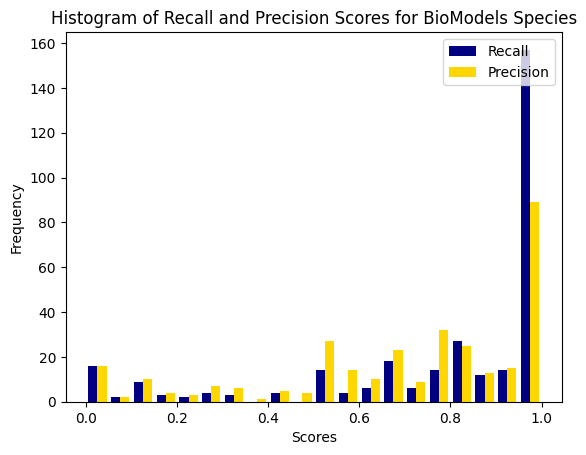

In [25]:
df1 = results_llama.groupby('model')[['recall_formula', 'precision_formula']].mean()
ax = plt.gca()
ax.hist(x=[df1['recall_formula'], df1['precision_formula']], bins=20, color=['navy', 'gold'], label=['Recall', 'Precision'])
# ax.set_ylim(0, 120)
ax.set_xlabel('Scores')
ax.set_ylabel('Frequency')
ax.set_title('Histogram of Recall and Precision Scores for BioModels Species')
ax.legend(loc='upper right')
plt.savefig(os.path.join(output_dir, 'biomd_spec_hist.png'), dpi=300, bbox_inches='tight', pad_inches=0.0)

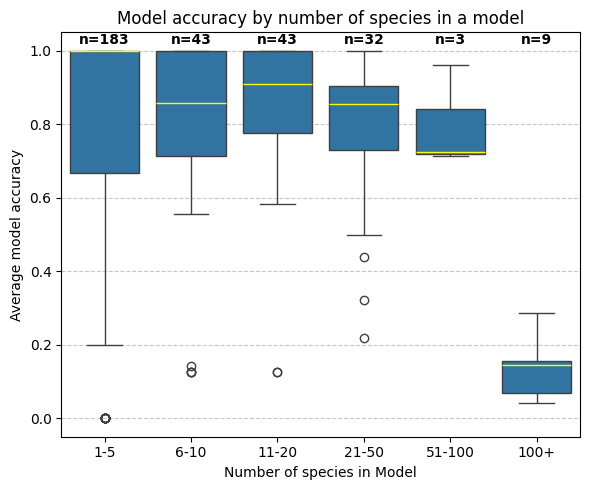

In [36]:
# Group models by number of species and calculate accuracy statistics
model_species_count = results_llama.groupby('model').size().reset_index(name='species_count')
model_accuracy = results_llama.groupby('model')['accuracy'].mean().reset_index()

# Merge the two dataframes
model_stats = pd.merge(model_species_count, model_accuracy, on='model')

# Create bins for species count to make the box plot more readable
bins = [0, 5, 10, 20, 50, 100, 1000]
labels = ['1-5', '6-10', '11-20', '21-50', '51-100', '100+']
model_stats['species_count_bin'] = pd.cut(model_stats['species_count'], bins=bins, labels=labels)

# Count number of models in each bin
bin_counts = model_stats['species_count_bin'].value_counts().reindex(labels, fill_value=0)

# Create the box plot
plt.figure(figsize=(6, 5))
ax = sns.boxplot(x='species_count_bin', y='accuracy', data=model_stats, medianprops={"color": "yellow", "linewidth": 1})

# Add counts above each box
for i, label in enumerate(labels):
    count = bin_counts[label]
    ax.text(i, 1.01, f'n={count}', ha='center', va='bottom', fontsize=10, color='black', fontweight='bold')

plt.title('Model accuracy by number of species in a model')
plt.xlabel('Number of species in Model')
plt.ylabel('Average model accuracy')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'accuracy_by_species_count.png'), dpi=300, bbox_inches='tight')
plt.show()


In [37]:
# excluding models with more than 100 species 
species_count_df = results_llama.groupby('model').size().reset_index(name='count')
# Merge this count back to the original dataframe
results_llama_count = pd.merge(results_llama, species_count_df, on='model', how='left')
# Rename the column to species_count
results_llama_count = results_llama_count.rename(columns={'count': 'species_count'})
results_llama_100 = results_llama_count[results_llama_count['species_count'] <= 100]
results_llama_100.to_csv(output_dir + 'biomd_chebi_direct_llama_100.csv')
print("\n\n<LLaMa 3.3 70b Instruct - BioModels Species (excluding models with more than 100 species)>")
print_results(output_dir + 'biomd_chebi_direct_llama_100.csv')



<LLaMa 3.3 70b Instruct - BioModels Species (excluding models with more than 100 species)>
Number of models assessed: 304
Number of models with predictions: 298
Average recall (per model) using formula: 0.81
Average precision (per model) using formula: 0.72
Average recall (per model) using ChEBI ID: 0.76
Average precision (per model) using ChEBI ID: 0.39
Average accuracy (per model): 0.81
Ave. total time (per model): 17.21
Ave. total time (per element, per model): 2.03
Ave. LLM time (per model): 16.58
Ave. LLM time (per element, per model): 1.96
Average number of predictions per row: 3.1262626262626263
